# Interpretabilidad y análisis de errores del modelo seleccionado

Este notebook desarrolla el objetivo específico 3 del proyecto: analizar el desempeño del modelo seleccionado en cada nivel de severidad, con énfasis en su capacidad para no subestimar los casos severos, e identificar mediante técnicas de interpretabilidad los indicadores con mayor contribución a sus estimaciones.

El modelo seleccionado es la configuración elegida en `03_busqueda_modelos.ipynb`: un modelo lineal regularizado (ElasticNet) en la formulación de regresión con umbrales, que estima el SII como un valor continuo y lo convierte en un nivel con tres umbrales. Se entrena con el conjunto principal de predictores, que reúne las variables demográficas, las variables físicas tabulares y el resumen de la actigrafía. Su evaluación usa validación cruzada anidada: cinco particiones externas estratificadas por SII, repetidas cinco veces. En cada partición externa, una validación interna de tres particiones elige los hiperparámetros del modelo, la estrategia de tratamiento de los faltantes y el exponente de ponderación α de los niveles. Este notebook no entrena modelos nuevos: reconstruye esa misma evaluación a partir del registro de la configuración seleccionada, carga sus predicciones y sus 25 modelos ajustados, y comprueba que reproducen el QWK registrado.

En un tamizaje, subestimar a un participante con uso problemático moderado o severo es más costoso que remitir a uno que no lo necesita. Por eso el QWK, que penaliza igual los errores hacia arriba y hacia abajo, se complementa con el desempeño por nivel y con un escenario de remisión. El notebook se organiza así:

1. Datos, particiones y modelos de la configuración seleccionada.
2. Desempeño por nivel de severidad: matriz de confusión, recall por nivel, tasa de subestimación y distribución de los casos severos entre los niveles asignados.
3. Escenario de tamizaje: remisión de todo participante con nivel estimado moderado o severo.
4. Contribución de las variables, con valores SHAP, y estabilidad de su orden entre repeticiones.
5. Errores por sexo y por grupo de edad.
6. Tablas exportadas y conclusiones.

Todas las salidas son agregadas: ninguna tabla contiene filas por participante ni identificadores.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from scipy import stats

from piu_severity.config import FIGURES_DIR, INTERIM_DATA_DIR, TABLES_DIR
from piu_severity.data.clean import clean_values
from piu_severity.data.load import list_actigraphy_ids, load_train
from piu_severity.evaluation.inference import (
    SEVERE_LEVEL,
    SEVERE_RECALL_MAX_SD,
    assigned_level_distribution,
    level_hits_by_repeat,
    participant_bootstrap_ci,
    participant_hit_rates,
)
from piu_severity.evaluation.interpretation import (
    DESCRIPTIVE_TOP_K,
    STABILITY_MIN_SPEARMAN,
    STABILITY_TOP_K,
    coefficient_signs,
    explain_folds,
    importance_by_repeat,
    instrument_group,
    order_is_stable,
    original_variable,
    ranking_stability,
    stack_contributions,
    top_targets,
    variable_instrument,
)
from piu_severity.evaluation.metrics import (
    SII_LEVELS,
    UNDERESTIMATION_LEVELS,
    as_levels,
    underestimation_rate,
)
from piu_severity.evaluation.persistence import (
    CACHE_VERSION,
    clear_pipeline_memory,
    run_configurations_cached,
)
from piu_severity.evaluation.reporting import metric_summary
from piu_severity.evaluation.screening import (
    REFERRAL_LEVEL,
    level_referral_by_repeat,
    participant_bootstrap_screening,
    participant_referral_rates,
    referral_consistency,
    screening_by_repeat,
)
from piu_severity.evaluation.selection import chosen_value_counts
from piu_severity.evaluation.subgroups import (
    AGE_GROUPS,
    age_group,
    subgroup_metrics_by_repeat,
    subgroup_summary,
)
from piu_severity.evaluation.validation import (
    N_OUTER_REPEATS,
    N_OUTER_SPLITS,
    mean_confusion_matrix,
    outer_splits,
    summarize_by_repeat,
)
from piu_severity.features.actigraphy import (
    load_actigraphy_summary,
    usable_actigraphy_mask,
)
from piu_severity.features.build import build_analytic_dataset
from piu_severity.features.groups import TARGET_COLUMN, experiment_feature_sets
from piu_severity.models.pipelines import available_workers
from piu_severity.models.registry import check_result, load_record, rebuild_task
from piu_severity.visualization.figures import save_figure

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

# Figuras y tablas del notebook, en carpetas con su nombre.
FIGURAS = FIGURES_DIR / "04_interpretabilidad_errores"
TABLAS = TABLES_DIR / "04_interpretabilidad_errores"
# Caché de evaluaciones del notebook 03: guarda las predicciones y los modelos
# ajustados de la configuración seleccionada. Está bajo data/interim, que git
# ignora, porque contiene predicciones por participante.
CARPETA_CACHE = INTERIM_DATA_DIR / "03_busqueda_modelos" / "cache"
# Caché de Pipeline(memory=...) de este notebook: solo se usa si hay que volver a
# ajustar alguna partición, y se libera al final.
CARPETA_MEMORIA = (
    INTERIM_DATA_DIR
    / "04_interpretabilidad_errores"
    / "pipeline_memory"
    / f"v{CACHE_VERSION}"
)

# Con True se vuelve a ajustar la evaluación aunque exista en el caché.
RECALCULAR = False
# Procesos en paralelo si hay que ajustar particiones: todos los núcleos menos dos.
N_PROCESOS = available_workers("linear", os.cpu_count())

NIVELES_SII = {0: "ninguno", 1: "leve", 2: "moderado", 3: "severo"}
NOMBRES_CONJUNTOS = {"main": "principal"}
NOMBRES_ALGORITMOS = {"linear": "lineal regularizado (ElasticNet)"}
NOMBRES_FORMULACIONES = {"threshold_regression": "regresión con umbrales"}
NOMBRES_ESTRATEGIAS = {"simple": "simple con indicadores", "iterative": "iterativa"}
NOMBRES_GRILLAS = {"original": "original", "extended": "ampliada"}
NOMBRES_GRUPOS = {
    "demographic": "demográfico",
    "physical": "físico tabular",
    "actigraphy": "actigrafía",
}

## 1. Datos, particiones y modelos de la configuración seleccionada

Esta sección reconstruye el conjunto analítico y las particiones externas con las mismas funciones del paquete que usó la búsqueda de modelos. Primero verifica que reproducen las cifras de la Entrega 2: 2.736 participantes con SII, 34 de ellos severos, y 36 predictores en el conjunto principal.

Luego lee el registro de la configuración seleccionada (`models/selected_configuration.json`) y reconstruye su evaluación con la misma firma: datos, particiones, grilla, semillas y versiones de las bibliotecas. Si la firma no coincide, la reconstrucción falla. Las predicciones y el modelo ajustado de cada partición externa se cargan del caché de evaluaciones. Si el caché no existe, la evaluación se ajusta de nuevo y se comprueba que su QWK medio no difiera del registrado en más de 0,005.

Por último, se verifica que cada participante tenga exactamente una predicción por repetición y que su nivel real coincida con el del conjunto analítico. Esa correspondencia es la que permite cruzar las predicciones con el sexo y la edad en la sección 5.

In [3]:
# Conjunto analítico: participantes con SII, con las reglas de limpieza y el
# resumen de actigrafía del análisis exploratorio.
train = load_train()
etiquetados = train[train[TARGET_COLUMN].notna()].reset_index(drop=True)
analitico = build_analytic_dataset(
    clean_values(etiquetados), load_actigraphy_summary(list_actigraphy_ids())
)
y = as_levels(analitico[TARGET_COLUMN])
conjuntos = experiment_feature_sets(analitico.columns)

# Cifras de la Entrega 2 que el conjunto debe reproducir.
N_ETIQUETADOS_ENTREGA_2 = 2_736
N_SEVEROS_ENTREGA_2 = 34
N_PREDICTORES_PRINCIPAL_ENTREGA_2 = 36
assert len(analitico) == N_ETIQUETADOS_ENTREGA_2
assert analitico["id"].is_unique
assert int((y == SEVERE_LEVEL).sum()) == N_SEVEROS_ENTREGA_2
assert len(conjuntos["main"]) == N_PREDICTORES_PRINCIPAL_ENTREGA_2

# Particiones externas: cinco estratificadas por SII, repetidas cinco veces con
# la semilla 42 + r en la repetición r; son las mismas de la búsqueda.
particiones = outer_splits(y)
assert len(particiones) == N_OUTER_SPLITS * N_OUTER_REPEATS

distribucion_sii = (
    pd.Series(y)
    .map(NIVELES_SII)
    .value_counts()
    .reindex(NIVELES_SII.values())
    .rename_axis("SII")
    .to_frame("participantes")
)
distribucion_sii["%"] = (100 * distribucion_sii["participantes"] / len(y)).round(1)

# Predictores del conjunto principal por grupo, con la actigrafía aparte.
predictores_por_grupo = (
    pd.Series(
        [
            NOMBRES_GRUPOS[instrument_group(variable_instrument(c))]
            for c in conjuntos["main"]
        ]
    )
    .value_counts()
    .reindex(NOMBRES_GRUPOS.values())
    .rename_axis("grupo")
    .to_frame("predictores")
)
display(distribucion_sii)
predictores_por_grupo

,participantes,%
SII,,
ninguno,1594,58.3
leve,730,26.7
moderado,378,13.8
severo,34,1.2


,predictores
grupo,
demográfico,3
físico tabular,30
actigrafía,3


In [4]:
# Registro de la configuración seleccionada: la entrada "evaluation" es la
# evaluación de la selección guardada con sus modelos ajustados.
registro = load_record()
entrada = registro["selected"]["evaluation"]
configuracion = entrada["config"]
assert entrada["name_suffix"].endswith("__models")

pd.Series(
    {
        "algoritmo": NOMBRES_ALGORITMOS[configuracion["algorithm"]],
        "formulación": NOMBRES_FORMULACIONES[configuracion["formulation"]],
        "conjunto de predictores": NOMBRES_CONJUNTOS[configuracion["feature_set"]],
        "grilla de hiperparámetros": NOMBRES_GRILLAS[registro["selected"]["grid"]],
        "particiones externas registradas": entrada["n_folds"],
        "QWK medio registrado": round(entrada["mean_qwk"], 3),
    },
    name="configuración seleccionada",
).to_frame()

,configuración seleccionada
algoritmo,lineal regularizado (ElasticNet)
formulación,regresión con umbrales
conjunto de predictores,principal
grilla de hiperparámetros,original
particiones externas registradas,25
QWK medio registrado,0.365


In [5]:
# Reconstrucción de la evaluación con la firma del registro y carga del caché:
# predicciones y modelo ajustado de cada partición externa.
tarea = rebuild_task(
    entrada,
    analitico[conjuntos[configuracion["feature_set"]]],
    y,
    particiones,
    memory=str(CARPETA_MEMORIA),
    keep_estimators=True,
)
inicio = time.perf_counter()
seleccionada = run_configurations_cached(
    [tarea],
    cache_dir=CARPETA_CACHE,
    n_jobs=N_PROCESOS,
    force=RECALCULAR,
    verbose=5,
)[tarea.name]
print(f"Minutos en esta ejecución: {(time.perf_counter() - inicio) / 60:.1f}")

# El resultado reproduce el registrado, hay un modelo por partición y cada
# participante tiene una predicción por repetición, con su nivel real.
diferencia_qwk = check_result(seleccionada, entrada)
assert all(seleccionada.estimators[(s.repeat, s.fold)] is not None for s in particiones)
predicciones = seleccionada.predictions
assert len(predicciones) == len(y) * N_OUTER_REPEATS
assert (predicciones.groupby("repeat")["position"].nunique() == len(y)).all()
assert np.array_equal(
    predicciones["y_true"].to_numpy(), y[predicciones["position"].to_numpy()]
)

conteo = seleccionada.counts()
print(
    f"Particiones cargadas: {conteo['loaded']}; ajustadas de nuevo: {conteo['computed']}"
)
print(
    f"QWK medio: {seleccionada.folds['qwk'].mean():.4f} "
    f"(diferencia con el registro: {diferencia_qwk:+.4f})"
)

Minutos en esta ejecución: 0.0
Particiones cargadas: 25; ajustadas de nuevo: 0
QWK medio: 0.3652 (diferencia con el registro: +0.0000)


[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.


In [6]:
# Tratamiento elegido por la validación interna en cada partición externa: la
# estrategia de faltantes y el exponente de ponderación α de los niveles.
parametros = list(seleccionada.folds["best_params"])
estrategias = chosen_value_counts(parametros, "preprocess__strategy")
exponentes = chosen_value_counts(parametros, "model__weight_power")
assert estrategias.idxmax() == registro["selected"]["most_frequent_strategy"]
assert estrategias.sum() == exponentes.sum() == len(particiones)

pd.concat(
    {
        "estrategia de faltantes": estrategias.rename(index=NOMBRES_ESTRATEGIAS),
        "exponente de ponderación α": exponentes.rename(index=lambda a: f"α = {a:g}"),
    },
    names=["hiperparámetro", "valor"],
).to_frame("particiones externas")

particiones externas
hiperparámetro             valor                                       
estrategia de faltantes    iterativa                                 20
                           simple con indicadores                     5
exponente de ponderación α α = 0.5                                   25

### Conclusión

- **Conjunto analítico.** Reproduce las cifras de la Entrega 2. Hay 2.736 participantes con SII: el 58,3 % en el nivel ninguno, el 26,7 % en leve, el 13,8 % en moderado y el 1,2 % en severo, que son 34 casos. El conjunto principal tiene 36 predictores: 3 demográficos, 30 físicos tabulares y 3 de actigrafía.
- **Evaluación reconstruida.** La firma coincide con la del registro y las 25 particiones externas se cargan del caché sin volver a ajustarse. El QWK medio es 0,365, igual al registrado, y cada participante tiene exactamente una predicción por repetición.
- **Tratamiento elegido.** La validación interna eligió la imputación iterativa en 20 de las 25 particiones y la imputación simple con indicadores de ausencia en las otras 5. El exponente de ponderación α fue 0,5 en las 25.

Como el tratamiento de los faltantes cambia entre particiones, los 25 modelos no comparten exactamente los mismos predictores transformados: los cinco con imputación simple incluyen un indicador de ausencia por instrumento. Esto se tiene en cuenta al agregar las contribuciones de las variables en la sección 4.

## 2. Desempeño por nivel de severidad

El QWK resume el acuerdo entre el nivel real y el asignado, pero es simétrico: subestimar o sobrestimar en la misma magnitud cuesta lo mismo. Para un tamizaje importa también dónde se equivoca el modelo, sobre todo en los niveles moderado y severo. Esta sección lo describe así:

- **Métricas por repetición.** En cada repetición, cada participante se predice exactamente una vez. Por eso, el recall de cada nivel y la tasa de subestimación se calculan sobre las predicciones de la repetición, y el QWK es la media de sus cinco particiones. Se reportan la media y la desviación estándar entre las cinco repeticiones; esa desviación describe la estabilidad frente a la partición de los datos.
- **Tasa de subestimación.** Es la proporción de participantes con SII moderado o severo a los que se asigna un nivel inferior al real:

$$
\text{subestimación} = \frac{\#\{i : y_i \in \{2, 3\},\ \hat{y}_i < y_i\}}{\#\{i : y_i \in \{2, 3\}\}}
$$

  Se reporta también solo para el nivel moderado, como descripción. En el nivel severo, toda asignación incorrecta es una subestimación, así que su tasa es uno menos su recall. En su lugar se reporta a qué niveles se asignan los participantes severos.
- **Incertidumbre.** Las repeticiones reutilizan a los mismos participantes, así que la desviación entre repeticiones no mide la incertidumbre de generalización. Para cada métrica por nivel se calcula además un intervalo del 95 % remuestreando participantes, cada uno con sus cinco repeticiones, 10.000 veces.
- **Nivel severo.** Con 34 casos, su recall se reporta por repetición con su intervalo de Wilson del 95 %, y se aplica la regla de estabilidad de la formulación: si la desviación estándar entre repeticiones superara 0,10 (unos tres casos), la evaluación se extendería a diez repeticiones. Se reporta también cuántos participantes severos reciben el mismo nivel en todas las repeticiones.

In [7]:
# Métricas por repetición: el QWK es la media de las cinco particiones de la
# repetición; el recall por nivel y la subestimación se calculan sobre sus
# predicciones, donde cada participante se estima una vez.
por_repeticion = summarize_by_repeat(seleccionada.folds, predicciones)
NIVEL_MODERADO = UNDERESTIMATION_LEVELS[0]
por_repeticion["underestimation_moderate"] = pd.Series(
    {
        repeticion: underestimation_rate(
            grupo["y_true"], grupo["y_pred"], levels=(NIVEL_MODERADO,)
        )
        for repeticion, grupo in predicciones.groupby("repeat")
    }
)

# Las cifras agregadas coinciden con las del registro de la configuración.
seleccion_registrada = registro["selected"]
assert np.isclose(
    por_repeticion["qwk"].std(), seleccion_registrada["qwk_sd_between_repeats"]
)
assert np.isclose(
    por_repeticion["underestimation"].mean(),
    seleccion_registrada["underestimation_moderate_or_severe"],
)
assert np.isclose(
    por_repeticion[f"recall_{SEVERE_LEVEL}"].mean(),
    seleccion_registrada["severe_recall"],
)

ETIQUETAS_METRICAS = {
    "qwk": "QWK",
    **{f"recall_{nivel}": f"recall {NIVELES_SII[nivel]}" for nivel in SII_LEVELS},
    "underestimation": "subestimación moderado o severo",
    "underestimation_moderate": "subestimación moderado",
}
resumen_repeticiones = por_repeticion.agg(["mean", "std"]).rename(
    index={"mean": "media", "std": "desviación"}
)
(
    pd.concat([por_repeticion.rename_axis("repetición"), resumen_repeticiones])
    .rename(columns=ETIQUETAS_METRICAS)
    .round(3)
)

,QWK,recall ninguno,recall leve,recall moderado,recall severo,subestimación moderado o severo,subestimación moderado
0,0.357,0.664,0.371,0.339,0.0,0.689,0.661
1,0.365,0.651,0.426,0.315,0.0,0.711,0.685
2,0.375,0.672,0.322,0.426,0.0,0.609,0.574
3,0.370,0.651,0.433,0.288,0.0,0.735,0.712
4,0.359,0.651,0.370,0.360,0.0,0.670,0.640
media,0.365,0.658,0.384,0.346,0.0,0.683,0.654
desviación,0.007,0.010,0.046,0.052,0.0,0.048,0.052


In [8]:
# Intervalo del 95 % de cada métrica por nivel, remuestreando participantes con
# sus cinco repeticiones (10.000 remuestreos). El recall de un nivel es la media
# de las tasas de acierto de sus participantes, y la subestimación, la media de
# sus tasas de asignación a un nivel inferior.
def tasas_subestimacion(niveles: tuple[int, ...]) -> pd.Series:
    """Proporción de repeticiones en que cada participante recibe un nivel inferior."""
    casos = predicciones[predicciones["y_true"].isin(niveles)]
    inferior = (casos["y_pred"] < casos["y_true"]).astype(float)
    return inferior.groupby(casos["position"]).mean()


tasas = {
    **{
        f"recall_{nivel}": participant_hit_rates(predicciones, nivel)
        for nivel in SII_LEVELS
    },
    "underestimation": tasas_subestimacion(UNDERESTIMATION_LEVELS),
    "underestimation_moderate": tasas_subestimacion((NIVEL_MODERADO,)),
}
# La media de las tasas por participante es la media entre repeticiones.
for metrica, tasas_metrica in tasas.items():
    assert np.isclose(tasas_metrica.mean(), por_repeticion[metrica].mean())

resumen_desempeno = metric_summary(
    por_repeticion,
    intervals={
        metrica: participant_bootstrap_ci(tasas_metrica)
        for metrica, tasas_metrica in tasas.items()
    },
    sizes={metrica: len(tasas_metrica) for metrica, tasas_metrica in tasas.items()},
)
ETIQUETAS_RESUMEN = {
    "mean": "media",
    "std_between_repeats": "desviación entre repeticiones",
    "interval_low": "intervalo 95 % inferior",
    "interval_high": "intervalo 95 % superior",
    "n": "participantes",
}
(
    resumen_desempeno.rename(index=ETIQUETAS_METRICAS, columns=ETIQUETAS_RESUMEN)
    .rename_axis("métrica")
    .round(3)
)

,media,desviación entre repeticiones,intervalo 95 % inferior,intervalo 95 % superior,participantes
métrica,,,,,
QWK,0.365,0.007,NaN,NaN,<NA>
recall ninguno,0.658,0.010,0.636,0.680,1594
recall leve,0.384,0.046,0.355,0.414,730
recall moderado,0.346,0.052,0.303,0.389,378
recall severo,0.000,0.000,0.000,0.000,34
subestimación moderado o severo,0.683,0.048,0.643,0.722,412
subestimación moderado,0.654,0.052,0.611,0.697,378


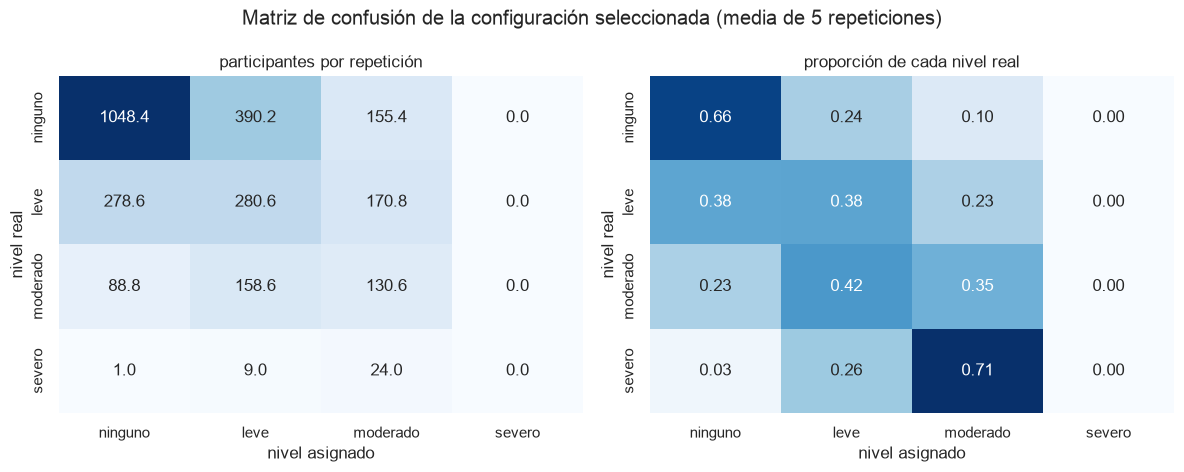

In [9]:
# Matriz de confusión promediada entre repeticiones: en conteos (participantes
# por celda en una repetición) y normalizada por fila, donde la diagonal es el
# recall de cada nivel.
etiquetas_niveles = list(NIVELES_SII.values())
matrices = {
    "participantes por repetición": mean_confusion_matrix(
        predicciones, normalize=False
    ),
    "proporción de cada nivel real": mean_confusion_matrix(
        predicciones, normalize=True
    ),
}
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.8))
for eje, (titulo, matriz), formato in zip(
    ejes, matrices.items(), (".1f", ".2f"), strict=True
):
    sns.heatmap(
        matriz.set_axis(etiquetas_niveles, axis=0).set_axis(etiquetas_niveles, axis=1),
        annot=True,
        fmt=formato,
        cmap="Blues",
        cbar=False,
        ax=eje,
    )
    eje.set_title(titulo)
    eje.set_xlabel("nivel asignado")
    eje.set_ylabel("nivel real")
fig.suptitle(
    "Matriz de confusión de la configuración seleccionada (media de 5 repeticiones)"
)
fig.tight_layout()
save_figure(fig, "matriz_confusion", FIGURAS)
plt.show()

In [10]:
# Nivel severo: aciertos de cada repetición con su intervalo de Wilson y regla
# de estabilidad de la formulación (desviación entre repeticiones mayor que 0,10).
aciertos_severo = level_hits_by_repeat(predicciones, SEVERE_LEVEL)
desviacion_severo = aciertos_severo["recall"].std()
severo_inestable = bool(desviacion_severo > SEVERE_RECALL_MAX_SD)
assert severo_inestable == seleccion_registrada["severe_recall_unstable"]
print(
    f"Recall severo: {aciertos_severo['recall'].mean():.3f}; desviación entre "
    f"repeticiones {desviacion_severo:.3f} (límite {SEVERE_RECALL_MAX_SD:g}); "
    f"inestable: {severo_inestable}"
)

# Distribución de los participantes severos entre los niveles asignados, en cada
# repetición y en promedio.
severos = predicciones[predicciones["y_true"] == SEVERE_LEVEL]
distribucion_por_repeticion = (
    severos.groupby("repeat")["y_pred"]
    .value_counts(normalize=True)
    .unstack(fill_value=0.0)
    .reindex(columns=list(SII_LEVELS), fill_value=0.0)
)
assert np.allclose(
    distribucion_por_repeticion.mean().to_numpy(),
    assigned_level_distribution(predicciones, SEVERE_LEVEL)
    .reindex(list(SII_LEVELS), fill_value=0.0)
    .to_numpy(),
)
distribucion_severo = pd.concat(
    [
        distribucion_por_repeticion.rename_axis("repetición"),
        distribucion_por_repeticion.agg(["mean", "std"]).rename(
            index={"mean": "media", "std": "desviación"}
        ),
    ]
).rename(columns=NIVELES_SII)
display(
    aciertos_severo.rename(
        columns={
            "cases": "casos severos",
            "hits": "aciertos",
            "recall": "recall",
            "wilson_low": "Wilson inferior",
            "wilson_high": "Wilson superior",
        }
    )
    .rename_axis("repetición")
    .round(3)
)
distribucion_severo.rename_axis(columns="nivel asignado").round(3)

Recall severo: 0.000; desviación entre repeticiones 0.000 (límite 0.1); inestable: False


,casos severos,aciertos,recall,Wilson inferior,Wilson superior
repetición,,,,,
0,34,0,0.0,0.0,0.102
1,34,0,0.0,0.0,0.102
2,34,0,0.0,0.0,0.102
3,34,0,0.0,0.0,0.102
4,34,0,0.0,0.0,0.102


nivel asignado,ninguno,leve,moderado,severo
0,0.029,0.265,0.706,0.0
1,0.059,0.265,0.676,0.0
2,0.029,0.176,0.794,0.0
3,0.029,0.324,0.647,0.0
4,0.000,0.294,0.706,0.0
media,0.029,0.265,0.706,0.0
desviación,0.021,0.055,0.055,0.0


In [11]:
# Estabilidad de la asignación de cada participante severo entre repeticiones:
# cuántos reciben siempre el mismo nivel, y cuál.
niveles_por_severo = severos.groupby("position")["y_pred"]
mismo_nivel = niveles_por_severo.nunique() == 1
print(
    f"Participantes severos con el mismo nivel en las {N_OUTER_REPEATS} "
    f"repeticiones: {int(mismo_nivel.sum())} de {mismo_nivel.size}"
)
(
    niveles_por_severo.first()[mismo_nivel]
    .map(NIVELES_SII)
    .value_counts()
    .reindex(etiquetas_niveles, fill_value=0)
    .rename_axis("nivel asignado en todas las repeticiones")
    .to_frame("participantes severos")
)

Participantes severos con el mismo nivel en las 5 repeticiones: 23 de 34


,participantes severos
nivel asignado en todas las repeticiones,
ninguno,0
leve,4
moderado,19
severo,0


### Conclusión

- **Acuerdo global.** El QWK medio es 0,365 y varía poco entre repeticiones (de 0,357 a 0,375, con una desviación de 0,007).
- **Recall por nivel.** El modelo reconoce mejor el nivel ninguno (recall de 0,658; intervalo del 95 % de 0,636 a 0,680) que los niveles con uso problemático: 0,384 en leve (0,355 a 0,414) y 0,346 en moderado (0,303 a 0,389). Los recall de leve y moderado son también los que más varían entre repeticiones, con desviaciones de 0,046 y 0,052.
- **Subestimación.** El 68,3 % de los participantes moderados o severos recibe un nivel inferior al real (intervalo del 95 % de 64,3 % a 72,2 %; desviación entre repeticiones de 0,048). Como los moderados son 378 de esos 412 participantes, la tasa la determina sobre todo ese nivel: el 65,4 % de los moderados se subestima. Según la matriz de confusión, el 42 % de los moderados se asigna al nivel leve y el 23 % al nivel ninguno, es decir, dos niveles por debajo.
- **Sobrestimación.** Los errores hacia arriba también son frecuentes: el 24 % de los participantes sin uso problemático se asigna al nivel leve y el 10 % al moderado, y el 23 % de los leves se asigna al moderado.
- **Nivel severo.** Ningún participante recibe el nivel severo, de ningún nivel real y en ninguna repetición, así que el recall severo es 0 en las cinco. La desviación entre repeticiones es 0, por debajo del límite de 0,10, de modo que la regla de estabilidad no exige extender la evaluación. El intervalo por remuestreo de participantes es [0, 0], pero no informa sobre la incertidumbre, porque todas las tasas de acierto son 0. La cota informativa es la de Wilson: con 0 aciertos en 34 casos, el recall severo podría llegar a 0,102.
- **A dónde van los severos.** En promedio, el 70,6 % de los participantes severos se asigna al nivel moderado (de 64,7 % a 79,4 % según la repetición), el 26,5 % al leve y el 2,9 % al nivel ninguno. La asignación es estable: 23 de los 34 reciben el mismo nivel en las cinco repeticiones (19 siempre moderado y 4 siempre leve), y los otros 11 cambian de nivel según la partición.

El modelo nunca asigna el nivel severo, pero ubica a la mayoría de los severos en el nivel inmediatamente inferior. Ese error es el que el QWK penaliza menos y, en un tamizaje, es también el que menos importa si la remisión empieza en el nivel moderado. La sección 3 examina esa consecuencia directamente.

## 3. Escenario de tamizaje

Para valorar el potencial de los indicadores como insumo de un tamizaje, las predicciones se traducen a una decisión de remisión: se remite a todo participante con nivel estimado moderado o severo. Un participante es positivo si su SII real es moderado o severo. Con los verdaderos positivos ($VP$), falsos negativos ($FN$), falsos positivos ($FP$) y verdaderos negativos ($VN$), se reportan:

$$
\text{recall} = \frac{VP}{VP + FN}, \qquad
\text{especificidad} = \frac{VN}{VN + FP}, \qquad
\text{valor predictivo positivo} = \frac{VP}{VP + FP}, \qquad
\text{proporción remitida} = \frac{VP + FP}{n}
$$

La regla de remisión y la forma de reportar su variabilidad quedaron fijadas en el paquete antes de calcular estos resultados:

- **Estabilidad e incertidumbre.** Las métricas se calculan sobre las predicciones de cada repetición, y se reportan su media y su desviación entre repeticiones. Además, se calcula un intervalo del 95 % remuestreando participantes, cada uno con sus cinco repeticiones, 10.000 veces. Ese intervalo se calcula sobre los conteos acumulados de las cinco repeticiones. Para el recall, la especificidad y la proporción remitida, esa estimación es igual a la media entre repeticiones. Para el valor predictivo positivo puede diferir un poco, porque su denominador cambia entre repeticiones.
- **Remisión por nivel real.** Para cada nivel se reporta qué proporción de sus participantes se remite. En el nivel ninguno, esa proporción es la de remisiones innecesarias; en los niveles moderado y severo, es la de casos detectados.
- **Casos severos.** Se reporta cuántos de los 34 participantes severos se remiten en cada repetición, con su intervalo de Wilson, y cuántos se remiten en todas las repeticiones, en ninguna o solo en algunas. Esta cifra responde si el modelo, aunque no asigne el nivel severo, logra que esos participantes lleguen a una evaluación.

No existe un umbral clínico de desempeño aceptable para este escenario, así que los resultados se leen como evidencia exploratoria y no como una validación clínica.

In [12]:
# Escenario de tamizaje: se remite a todo participante con nivel estimado
# moderado o severo. La regla y la forma de reportar su variabilidad quedaron
# fijadas en el paquete antes de calcular estos resultados.
assert REFERRAL_LEVEL == NIVEL_MODERADO
tamizaje_por_repeticion = screening_by_repeat(predicciones)
bootstrap_tamizaje = participant_bootstrap_screening(predicciones)
# Sobre los conteos acumulados, la estimación coincide con la media entre
# repeticiones en todas las métricas salvo el valor predictivo positivo.
for metrica in ("recall", "specificity", "referred_share"):
    assert np.isclose(
        bootstrap_tamizaje.loc[metrica, "estimate"],
        tamizaje_por_repeticion[metrica].mean(),
    )

n_positivos = int((y >= REFERRAL_LEVEL).sum())
resumen_tamizaje = metric_summary(
    tamizaje_por_repeticion,
    intervals={
        metrica: (
            bootstrap_tamizaje.loc[metrica, "interval_low"],
            bootstrap_tamizaje.loc[metrica, "interval_high"],
        )
        for metrica in tamizaje_por_repeticion.columns
    },
    sizes={
        "recall": n_positivos,
        "specificity": len(y) - n_positivos,
        "referred_share": len(y),
    },
)
ETIQUETAS_TAMIZAJE = {
    "recall": "recall",
    "specificity": "especificidad",
    "ppv": "valor predictivo positivo",
    "referred_share": "proporción remitida",
}
display(
    pd.concat(
        [
            tamizaje_por_repeticion.rename_axis("repetición"),
            tamizaje_por_repeticion.agg(["mean", "std"]).rename(
                index={"mean": "media", "std": "desviación"}
            ),
        ]
    )
    .rename(columns=ETIQUETAS_TAMIZAJE)
    .round(3)
)
(
    resumen_tamizaje.rename(index=ETIQUETAS_TAMIZAJE, columns=ETIQUETAS_RESUMEN)
    .rename_axis("métrica")
    .round(3)
)

,recall,especificidad,valor predictivo positivo,proporción remitida
0,0.369,0.854,0.309,0.180
1,0.345,0.880,0.336,0.154
2,0.456,0.826,0.318,0.216
3,0.318,0.889,0.338,0.142
4,0.388,0.849,0.314,0.186
media,0.375,0.860,0.323,0.176
desviación,0.052,0.025,0.013,0.029


,media,desviación entre repeticiones,intervalo 95 % inferior,intervalo 95 % superior,participantes
métrica,,,,,
recall,0.375,0.052,0.334,0.418,412
especificidad,0.860,0.025,0.847,0.872,2324
valor predictivo positivo,0.323,0.013,0.283,0.361,<NA>
proporción remitida,0.176,0.029,0.163,0.188,2736


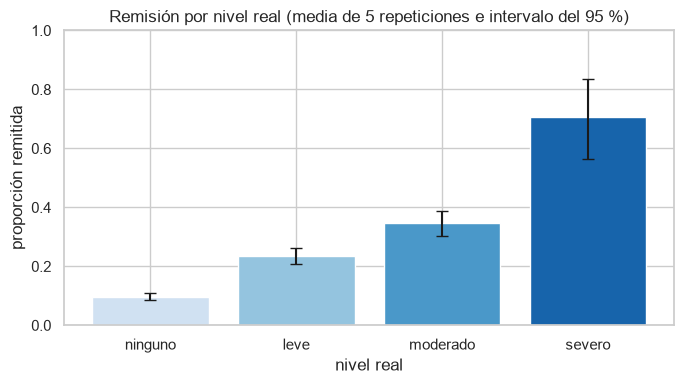

,participantes,remitidos por repetición (media),proporción remitida,desviación entre repeticiones,intervalo 95 % inferior,intervalo 95 % superior
nivel real,,,,,,
ninguno,1594,155.4,0.097,0.017,0.085,0.111
leve,730,170.8,0.234,0.043,0.208,0.261
moderado,378,130.6,0.346,0.052,0.303,0.389
severo,34,24.0,0.706,0.055,0.565,0.835


In [13]:
# Proporción remitida de cada nivel real, por repetición, con su intervalo del
# 95 % por remuestreo de participantes.
remision_por_repeticion = {
    nivel: level_referral_by_repeat(predicciones, nivel) for nivel in SII_LEVELS
}
filas = {}
for nivel, remision in remision_por_repeticion.items():
    bajo, alto = participant_bootstrap_ci(
        participant_referral_rates(predicciones, nivel)
    )
    filas[NIVELES_SII[nivel]] = {
        "participantes": int(remision["cases"].iloc[0]),
        "remitidos por repetición (media)": remision["referred"].mean(),
        "proporción remitida": remision["share"].mean(),
        "desviación entre repeticiones": remision["share"].std(),
        "intervalo 95 % inferior": bajo,
        "intervalo 95 % superior": alto,
    }
remision_por_nivel = pd.DataFrame.from_dict(filas, orient="index").rename_axis(
    "nivel real"
)

fig, eje = plt.subplots(figsize=(7, 4))
eje.bar(
    remision_por_nivel.index,
    remision_por_nivel["proporción remitida"],
    yerr=[
        remision_por_nivel["proporción remitida"]
        - remision_por_nivel["intervalo 95 % inferior"],
        remision_por_nivel["intervalo 95 % superior"]
        - remision_por_nivel["proporción remitida"],
    ],
    color=sns.color_palette("Blues", len(remision_por_nivel)),
    capsize=4,
)
eje.set_ylim(0, 1)
eje.set_xlabel("nivel real")
eje.set_ylabel("proporción remitida")
eje.set_title("Remisión por nivel real (media de 5 repeticiones e intervalo del 95 %)")
fig.tight_layout()
save_figure(fig, "remision_por_nivel", FIGURAS)
plt.show()
remision_por_nivel.round(3)

In [14]:
# Participantes severos remitidos en cada repetición, de 34, con su intervalo de
# Wilson, y cuántos participantes moderados y severos se remiten en todas las
# repeticiones, en ninguna o solo en algunas.
display(
    remision_por_repeticion[SEVERE_LEVEL]
    .rename(
        columns={
            "cases": "casos severos",
            "referred": "remitidos",
            "share": "proporción remitida",
            "wilson_low": "Wilson inferior",
            "wilson_high": "Wilson superior",
        }
    )
    .rename_axis("repetición")
    .round(3)
)
(
    pd.DataFrame(
        {
            NIVELES_SII[nivel]: referral_consistency(
                participant_referral_rates(predicciones, nivel)
            )
            for nivel in UNDERESTIMATION_LEVELS
        }
    )
    .T.rename(
        columns={
            "always": "remitidos en todas las repeticiones",
            "never": "en ninguna",
            "sometimes": "en algunas",
            "participants": "participantes",
        }
    )
    .rename_axis("nivel real")
)

,casos severos,remitidos,proporción remitida,Wilson inferior,Wilson superior
repetición,,,,,
0,34,24,0.706,0.538,0.832
1,34,23,0.676,0.508,0.809
2,34,27,0.794,0.632,0.897
3,34,22,0.647,0.479,0.785
4,34,24,0.706,0.538,0.832


,remitidos en todas las repeticiones,en ninguna,en algunas,participantes
nivel real,,,,
moderado,92,195,91,378
severo,19,7,8,34


### Conclusión

- **Proporción remitida.** La regla remite al 17,6 % de los participantes (intervalo del 95 % de 16,3 % a 18,8 %), unos 481 por repetición.
- **Detección de casos.** El recall es 0,375 (de 0,334 a 0,418): de cada ocho participantes con SII moderado o severo, se remiten tres. Varía entre repeticiones de 0,318 a 0,456, con una desviación de 0,052. Como los moderados son 378 de los 412 positivos, este recall depende sobre todo de ellos.
- **Especificidad y valor predictivo positivo.** La especificidad es 0,860 (de 0,847 a 0,872) y el valor predictivo positivo, 0,323 (de 0,283 a 0,361). Uno de cada tres remitidos tiene un SII moderado o severo. De los demás, unos 155 por repetición no tienen uso problemático y unos 171 lo tienen leve.
- **Comparación con una remisión al azar.** Si se remitiera al azar a la misma proporción de participantes, se detectaría en promedio el 17,6 % de los positivos, y el valor predictivo positivo sería igual a la prevalencia: 412 de 2.736, es decir, 15,1 %. El modelo duplica ambas cifras.
- **Remisión por nivel real.** La proporción remitida crece con la severidad: 9,7 % de los participantes sin uso problemático, 23,4 % de los leves, 34,6 % de los moderados y 70,6 % de los severos.
- **Casos severos.** Aunque el modelo no asigna el nivel severo, remite en promedio a 24 de los 34 participantes severos, porque los ubica en el nivel moderado. Por repetición, remite entre 22 y 27, con intervalos de Wilson que van de 0,48 a 0,90; el intervalo por remuestreo de participantes va de 0,565 a 0,835. Por participante, 19 de los 34 severos se remiten en las cinco repeticiones, 7 en ninguna y 8 solo en algunas.
- **Casos moderados.** En cambio, más de la mitad de los moderados (195 de 378) no se remite en ninguna repetición, y solo 92 se remiten en todas.

En un escenario que remite desde el nivel moderado, que el modelo no asigne el nivel severo pesa menos de lo que sugiere su recall severo nulo: siete de cada diez severos llegan a la remisión. El límite principal del escenario está en los moderados, que son la mayoría de los positivos y de los que se remite solo uno de cada tres. Con 34 casos severos, la proporción de severos remitidos tiene un intervalo amplio. Además, como no existe un umbral clínico de desempeño aceptable, estas cifras son evidencia exploratoria.